# FIFA World Cup 2026 — Objective 1, Task 3

## Shooting Accuracy of Advanced vs Eliminated Teams

**Analytic question:**  
Do teams that advanced from the FIFA World Cup 2026 group stage have significantly higher shooting accuracy than teams that were eliminated?

**Focal point:** Shooting accuracy.

This task is distinct from Task 1, which investigated chance quality using xG per shot.

## Data source and scope

The analysis uses team-level shooting data for all **48 FIFA World Cup 2026 group-stage teams**.

For each team, the dataset contains:

- Group
- Team
- Outcome (`Advanced` or `Eliminated`)
- Total shots across the three group-stage matches
- Shots on target across the three group-stage matches
- A source URL for the team's FBref World Cup shooting match log

Only the **three group-stage matches** are included for each team. Knockout-stage matches are excluded.

The derived variable is:

**Shooting Accuracy (%) = (Shots on Target / Total Shots) × 100**


## 1. Import libraries and load the population dataset

The analysis is carried out in Python using `pandas`, `numpy`, `scipy`, and `matplotlib`.

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

population = pd.read_csv("FIFA_WC2026_Task3_Shooting_Accuracy_Population.csv")

# Recalculate the derived metric in Python to verify it independently.
population["Shooting_Accuracy"] = (
    population["Shots_on_Target"] / population["Total_Shots"] * 100
)

print("Population rows:", len(population))
print("\nOutcome counts:")
print(population["Outcome"].value_counts())

population.head()

ModuleNotFoundError: No module named 'pandas'

## 2. Data wrangling and validation

Before sampling, the data is checked for:

- missing values,
- duplicate teams,
- non-positive shot totals,
- impossible cases where shots on target exceed total shots,
- correct population size and outcome counts.

This demonstrates that the dataset is suitable for the statistical analysis.

In [ ]:
audit = {
    "Missing values": population.isna().sum().sum(),
    "Duplicate teams": population["Team"].duplicated().sum(),
    "Teams with Total_Shots <= 0": (population["Total_Shots"] <= 0).sum(),
    "Rows where Shots_on_Target > Total_Shots":
        (population["Shots_on_Target"] > population["Total_Shots"]).sum(),
    "Population teams": len(population),
    "Advanced teams": (population["Outcome"] == "Advanced").sum(),
    "Eliminated teams": (population["Outcome"] == "Eliminated").sum(),
}

pd.Series(audit, name="Value").to_frame()

,Value
Missing values,0
Duplicate teams,0
Teams with Total_Shots <= 0,0
Rows where Shots_on_Target > Total_Shots,0
Population teams,48
Advanced teams,32
Eliminated teams,16


## 3. Data preparation and sampling

### Population
The population is all **48 teams** that participated in the FIFA World Cup 2026 group stage:

- 32 Advanced teams
- 16 Eliminated teams

### Sample
A **proportionate stratified random sample** is used.

A 75% sample is drawn from each outcome group:

- 24 of 32 Advanced teams
- 12 of 16 Eliminated teams

This gives a final sample of **36 teams** and preserves the population ratio of 2:1.

A fixed `random_state=42` is used so the sample is reproducible.

In [ ]:
advanced_pop = population[population["Outcome"] == "Advanced"]
eliminated_pop = population[population["Outcome"] == "Eliminated"]

advanced_sample = advanced_pop.sample(n=24, random_state=42)
eliminated_sample = eliminated_pop.sample(n=12, random_state=42)

sample = pd.concat([advanced_sample, eliminated_sample], ignore_index=True)

print("Sample size:", len(sample))
print("\nSample outcome counts:")
print(sample["Outcome"].value_counts())

sample[["Group", "Team", "Outcome", "Total_Shots", "Shots_on_Target", "Shooting_Accuracy"]]

Sample size: 36

Sample outcome counts:
Outcome
Advanced      24
Eliminated    12
Name: count, dtype: int64


,Group,Team,Outcome,Total_Shots,Shots_on_Target,Shooting_Accuracy
0,L,Croatia,Advanced,24,11,45.833333
1,F,Sweden,Advanced,40,20,50.000000
2,J,Argentina,Advanced,34,15,44.117647
3,G,Egypt,Advanced,48,13,27.083333
4,D,Paraguay,Advanced,23,5,21.739130
5,D,USA,Advanced,44,15,34.090909
6,L,England,Advanced,58,20,34.482759
7,J,Austria,Advanced,27,8,29.629630
8,E,Germany,Advanced,53,22,41.509434
9,A,Mexico,Advanced,35,13,37.142857


## 4. Descriptive statistics

The sample is summarised using:

- sample size (`n`)
- mean
- median
- sample standard deviation
- minimum
- first quartile (Q1)
- third quartile (Q3)
- maximum

In [ ]:
descriptive = sample.groupby("Outcome")["Shooting_Accuracy"].agg(
    n="count",
    mean="mean",
    median="median",
    std="std",
    minimum="min",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    maximum="max"
)

descriptive.round(2)

,n,mean,median,std,minimum,Q1,Q3,maximum
Outcome,,,,,,,,
Advanced,24,36.15,36.16,8.61,20.59,30.13,42.16,50.00
Eliminated,12,30.72,28.75,8.05,21.88,23.99,35.16,48.39


### Descriptive interpretation

The mean shooting accuracy is compared between Advanced and Eliminated teams.  
A higher value means a larger percentage of a team's shots were on target.

In [ ]:
adv = sample.loc[sample["Outcome"] == "Advanced", "Shooting_Accuracy"]
elim = sample.loc[sample["Outcome"] == "Eliminated", "Shooting_Accuracy"]

mean_difference = adv.mean() - elim.mean()

print(f"Advanced mean shooting accuracy: {adv.mean():.2f}%")
print(f"Eliminated mean shooting accuracy: {elim.mean():.2f}%")
print(f"Observed mean difference: {mean_difference:.2f} percentage points")

Advanced mean shooting accuracy: 36.15%
Eliminated mean shooting accuracy: 30.72%
Observed mean difference: 5.43 percentage points


## 5. Visualisation

A boxplot is used to compare the distribution of shooting accuracy between the two groups.

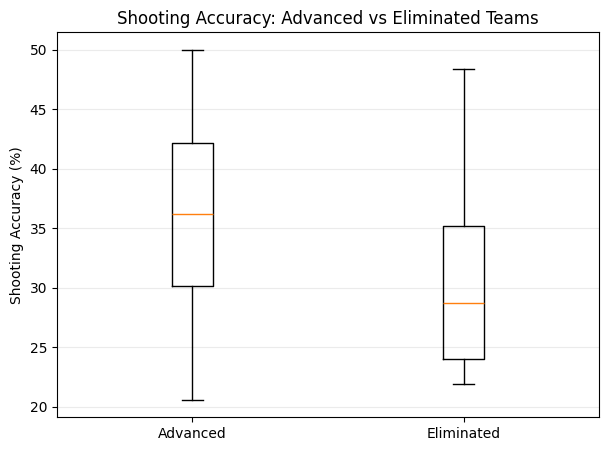

In [ ]:
plt.figure(figsize=(7, 5))
plt.boxplot(
    [adv, elim],
    tick_labels=["Advanced", "Eliminated"]
)
plt.ylabel("Shooting Accuracy (%)")
plt.title("Shooting Accuracy: Advanced vs Eliminated Teams")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 6. Inferential statistics — 95% confidence intervals

A 95% t-confidence interval is calculated for the mean shooting accuracy of each group.

The interval estimates the plausible range for the corresponding population mean based on the sample.

In [ ]:
def mean_t_ci(series, confidence=0.95):
    x = np.asarray(series, dtype=float)
    n = len(x)
    mean = x.mean()
    sd = x.std(ddof=1)
    se = sd / np.sqrt(n)
    t_crit = stats.t.ppf((1 + confidence) / 2, df=n - 1)
    return mean, mean - t_crit * se, mean + t_crit * se

adv_ci = mean_t_ci(adv)
elim_ci = mean_t_ci(elim)

ci_table = pd.DataFrame({
    "Group": ["Advanced", "Eliminated"],
    "Mean (%)": [adv_ci[0], elim_ci[0]],
    "95% CI Lower (%)": [adv_ci[1], elim_ci[1]],
    "95% CI Upper (%)": [adv_ci[2], elim_ci[2]]
})

ci_table.round(2)

,Group,Mean (%),95% CI Lower (%),95% CI Upper (%)
0,Advanced,36.15,32.51,39.78
1,Eliminated,30.72,25.60,35.83


## 7. Inferential statistics — Welch two-sample t-test

Because the two groups are independent and equal population variances are not assumed, a **Welch independent two-sample t-test** is used.

### Hypotheses

**H0:** mean shooting accuracy of Advanced teams = mean shooting accuracy of Eliminated teams

**H1:** mean shooting accuracy of Advanced teams > mean shooting accuracy of Eliminated teams

The research question is directional, so the main test is **one-sided**.

**Significance level: α = 0.05**


In [ ]:
one_sided = stats.ttest_ind(
    adv,
    elim,
    equal_var=False,
    alternative="greater"
)

two_sided = stats.ttest_ind(
    adv,
    elim,
    equal_var=False
)

print(f"Welch t statistic: {one_sided.statistic:.4f}")
print(f"One-sided p-value: {one_sided.pvalue:.4f}")
print(f"Two-sided p-value (sensitivity check): {two_sided.pvalue:.4f}")

Welch t statistic: 1.8650
One-sided p-value: 0.0374
Two-sided p-value (sensitivity check): 0.0747


### Decision rule

- Reject **H0** if the one-sided p-value is less than 0.05.
- Otherwise, fail to reject **H0**.

The two-sided p-value is also shown as a sensitivity check, but it is not the primary test because the analytic question specifically asks whether Advanced teams have **higher** shooting accuracy.


In [ ]:
alpha = 0.05

if one_sided.pvalue < alpha:
    decision = "Reject H0"
    conclusion = (
        "There is statistically significant evidence at the 5% level "
        "that teams that advanced had higher mean shooting accuracy "
        "than teams that were eliminated."
    )
else:
    decision = "Fail to reject H0"
    conclusion = (
        "There is insufficient evidence at the 5% level "
        "that teams that advanced had higher mean shooting accuracy "
        "than teams that were eliminated."
    )

print("Decision:", decision)
print("\nConclusion:", conclusion)

Decision: Reject H0

Conclusion: There is statistically significant evidence at the 5% level that teams that advanced had higher mean shooting accuracy than teams that were eliminated.


## 8. Final interpretation

In the 36-team stratified sample:

- Advanced teams had mean shooting accuracy of approximately **36.15%**.
- Eliminated teams had mean shooting accuracy of approximately **30.72%**.
- The observed difference was approximately **5.43 percentage points**.

The one-sided Welch t-test gives a p-value of approximately **0.0374**. Because this is below 0.05, the null hypothesis is rejected for the pre-specified directional test.

Therefore, the sample provides evidence that teams that advanced from the group stage had higher mean shooting accuracy than teams that were eliminated.

This result should be interpreted as an **association** in the tournament data. It does not establish that higher shooting accuracy caused teams to advance.

## 9. Files used for this task

- `FIFA_WC2026_Task3_Shooting_Accuracy_Population.csv`
- This Jupyter Notebook

The population CSV contains the underlying 48-team analysis dataset and source URLs used to trace the shooting statistics.